# 02 · Recovery and Cortex-M4 execution
The firmware stores 44-byte packed calibration summaries and appends six-word journal transactions. A two-bank checkpoint preserves the newest complete generation and the most recent committed request, so its retry can still be acknowledged after compaction. This notebook reruns the C tests and checks the saved Renode execution trace.

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "har").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "results"

import subprocess
from har.model import DIM, VECTORS, rebuild
from har.native import DUPLICATE, IO, OK, Edit, Journal, pack_blocks

test_run = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
                          cwd=ROOT, text=True, capture_output=True, check=True)
print(test_run.stderr.strip())

test_all_checkpoint_boundaries_and_inactive_bank_erase (test_method.MethodTests.test_all_checkpoint_boundaries_and_inactive_bank_erase) ... ok
test_all_edit_boundaries_and_seeded_torn_masks (test_method.MethodTests.test_all_edit_boundaries_and_seeded_torn_masks) ... ok
test_checkpoint_receipt_ablation (test_method.MethodTests.test_checkpoint_receipt_ablation) ... ok
test_duplicate_conflict_and_reboot (test_method.MethodTests.test_duplicate_conflict_and_reboot) ... ok
test_edit_horizon_and_epoch (test_method.MethodTests.test_edit_horizon_and_epoch) ... ok
test_full_journal_compacts_and_uses_other_bank (test_method.MethodTests.test_full_journal_compacts_and_uses_other_bank) ... ok
test_packed_boundaries_and_word_crossings (test_method.MethodTests.test_packed_boundaries_and_word_crossings) ... ok
test_snapshot_cost_recovery_and_stale_acknowledgement (test_method.MethodTests.test_snapshot_cost_recovery_and_stale_acknowledgement) ... ok
test_snapshot_with_matched_receipt (test_method.Method

## Walk through an interrupted edit
The first three flash words are programmed. The fourth word is interrupted. After a fresh C state is reconstructed, the original class sums are recovered. Retrying commits the entire interval. A second retry returns the saved acknowledgement without another write.

In [2]:
rng = np.random.default_rng(17)
x = rng.integers(-100, 101, size=(12, VECTORS, DIM), dtype=np.int16)
labels = np.repeat(np.arange(6, dtype=np.uint8), 2)
edit = Edit(1, 0, 2, 0, 1)
journal = Journal(pack_blocks(x, labels, "packed"), slots=4)
assert journal.apply(edit, cut=3, mask=0xFFFF)[0] == IO
journal.reboot()
np.testing.assert_array_equal(journal.labels(), labels)
assert journal.apply(edit) == (OK, 6)
journal.reboot()
assert journal.apply(edit) == (DUPLICATE, 0)
assert journal.compact()[0] == OK
journal.reboot()
assert journal.apply(edit) == (DUPLICATE, 0)
fixed = labels.copy()
fixed[:2] = 1
np.testing.assert_array_equal(journal.stats()[0], rebuild(x, fixed)[0])
print("Recovered class counts:", journal.stats()[1].tolist())

Recovered class counts: [0, 16, 8, 8, 8, 8]


## Simulator checks and memory
The saved Renode runs compile and execute the same C core on a Cortex-M4 platform with the STM32F4 flash controller model. Three fixtures per dataset enroll from raw sensor windows and exercise reset and recovery. Instruction counts describe emulated work. Linker-section RAM excludes the test mailbox and stack.

,Dataset,Implementation,Calibration (B),Extra cache RAM (B),Edit (B),Edit erases,Edit path (insn),Boot after 3 edits (insn)
0,HAPT,Packed journal,1056,0,24,0,2728,24322
1,HAPT,Unpacked journal,2400,0,24,0,3418,34672
2,HAPT,Incremental vectors,4704,0,24,0,3820,40870
3,HAPT,Full-vector rebuild,4704,0,24,0,41434,40870
4,HAPT,RAM-cached vectors,4704,2400,24,0,3418,54296
5,HAPT,Two-bank snapshot,1056,0,180,1,23830,52497
6,MotionSense,Packed journal,1056,0,24,0,2728,24322
7,MotionSense,Unpacked journal,2400,0,24,0,3418,34672
8,MotionSense,Incremental vectors,4704,0,24,0,3820,40870
9,MotionSense,Full-vector rebuild,4704,0,24,0,41434,40870


,renode,compiler,executable_flash,static_firmware_ram,simulator_mailbox_ram,model_state_ram,logical_journal_bank_bytes,reserved_stm32f4_flash_bytes
0,Renode v1.17.0,arm-none-eabi-gcc (15:12.2.rel1-1) 12.2.1 2022...,5552,788,43388,760,564,393216


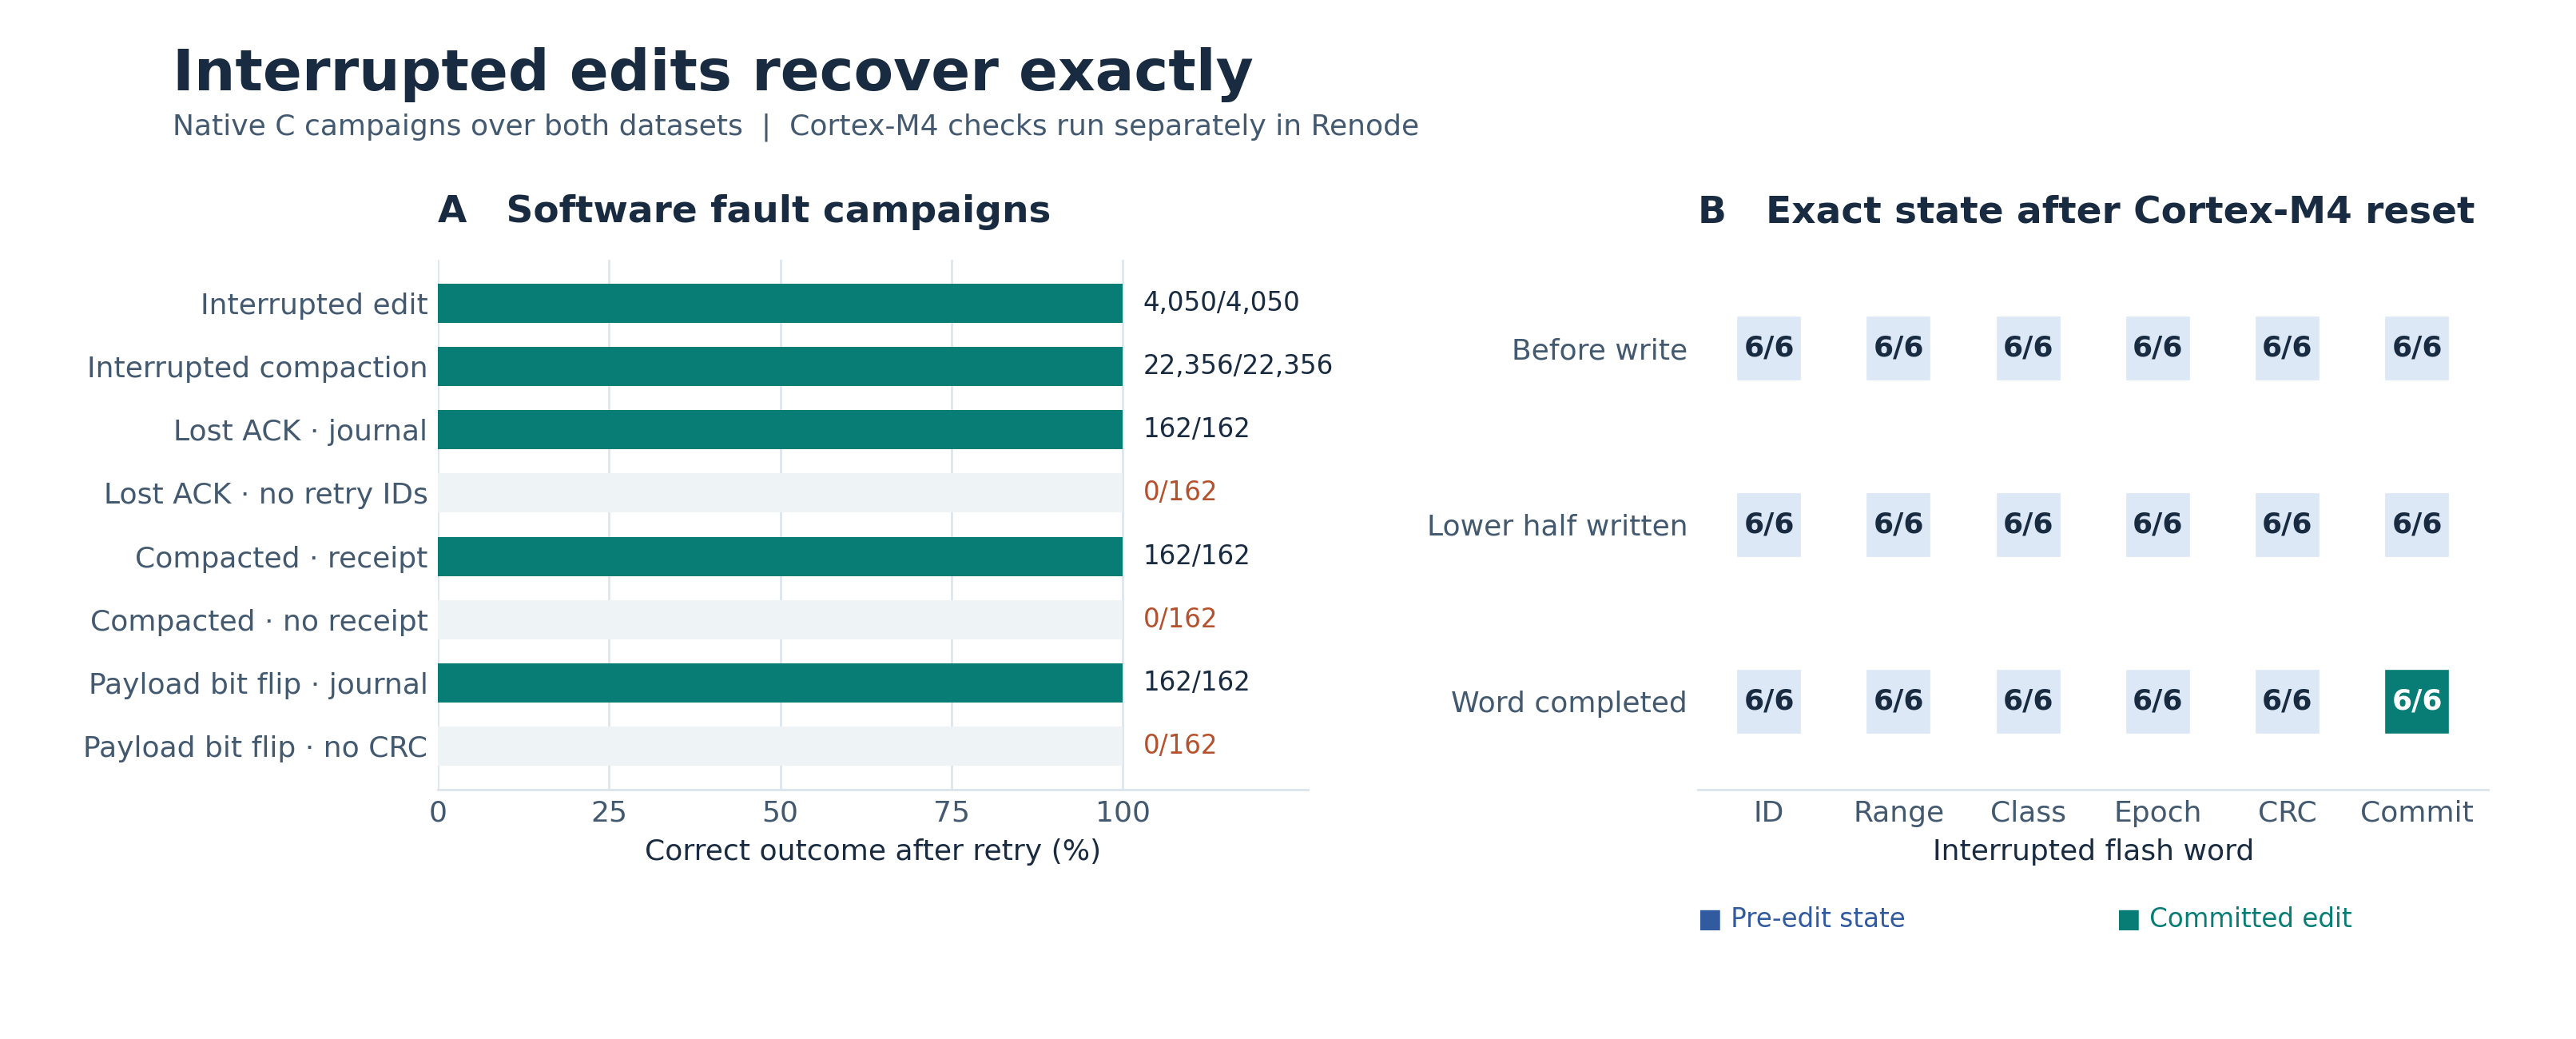

In [3]:
if os.environ.get("HAR_RERUN_RENODE") == "1":
    from har.emulator import run as run_renode
    run_renode(renode=os.environ.get("RENODE", "renode"),
               cross=os.environ.get("CROSS_COMPILE", "arm-none-eabi-"))

renode = pd.read_csv(RESULTS / "renode.csv")
assert (renode.loc[renode.case.str.endswith("_recovery"), "status"] == OK).all()
assert (renode.loc[renode.case == "clean_edit", "program_bytes"] == 24).all()
assert (renode.loc[renode.case == "compacted_latest", "status"] == DUPLICATE).all()
display(pd.read_csv(RESULTS / "tables" / "firmware_cost.csv"))
display(pd.read_csv(RESULTS / "firmware_memory.csv"))
display(Image(filename=str(RESULTS / "figures" / "fig1_recovery.png"), width=910))

In [4]:
display(pd.read_csv(RESULTS / "tables" / "recovery.csv"))
reset_rows = renode.case.str.fullmatch(r"(?:edit|compact|snapshot)_cut_[0-9]+_(?:before|torn_low_half|after)")
display(renode.loc[reset_rows].groupby("layout").size().rename("Cortex-M4 resets").to_frame())
display(pd.read_csv(RESULTS / "tables" / "stress_sequences.csv"))

,Dataset,Campaign,Method,Exact boot,Correct outcome after retry
0,HAPT,Lost acknowledgement across checkpoint,Remove checkpoint receipt,90/90,0/90
1,HAPT,Lost acknowledgement across checkpoint,Packed journal,90/90,90/90
2,HAPT,Compaction interrupted,Packed journal,12420/12420,12420/12420
3,HAPT,Lost acknowledgement,Remove retry IDs,90/90,0/90
4,HAPT,Lost acknowledgement,Packed journal,90/90,90/90
5,HAPT,Corrupted payload,Remove CRC validation,0/90,0/90
6,HAPT,Corrupted payload,Packed journal,90/90,90/90
7,HAPT,Edit interrupted,Packed journal,2250/2250,2250/2250
8,HAPT,Snapshot interrupted,Two-bank snapshot,810/810,810/810
9,MotionSense,Lost acknowledgement across checkpoint,Remove checkpoint receipt,72/72,0/72


,Cortex-M4 resets
layout,
packed,192
snapshot,30


,Dataset,streams,edits,retry_acks,resets,erase_calls,programmed_bytes
0,HAPT,90,5760,5760,3676,1213,342544
1,MotionSense,72,4608,4608,2906,940,272604


Re-run the Cortex-M4 campaign with Renode and the Arm GNU toolchain on the PATH.

```bash
python -m har.emulator
```